In [1]:
# =============================================================================
# These are the first two models we did for our project we Random Forest for 
# first two models. We did Random Forest Classifier for Task A in out project
# and Random Forest Regressor for Task B.
# =============================================================================

import sys

assert sys.version_info >= (3, 7)

In [3]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

In [4]:
import matplotlib.pyplot as plt

plt.rc('font', size=12)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=12)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

In [5]:
import numpy as np

np.random.seed(42)

In [6]:
import pandas as pd

DATA_FILE = "Final_SOCal_dataset.csv"
TRAIN_END_YEAR = 2015          # train: 1950–2015, test: 2016–2025

data = pd.read_csv(DATA_FILE)
data.head()

,station,name,date,year,tmin_lag1,dtr_lag1,dayofyear,days_since_rain,oni_lag,prcp_sum30,...,hot_night,coverage,prev_hot_nights,prev_mean_tmin,avg5_hot_days,prev_max_spell_days,hot_day_count,hot_night_count,anom_step,anom_interpolated
0,USC00046635+USW00093138,Palm_Springs,1950-05-01,1950,12.8,13.3,121,37.0,-1.2,0.8,...,0.0,0.973,NaN,NaN,NaN,NaN,9.0,4.0,-1.32,-1.166
1,USC00046635+USW00093138,Palm_Springs,1950-05-02,1950,12.8,14.8,122,38.0,-1.2,0.8,...,0.0,0.973,NaN,NaN,NaN,NaN,9.0,4.0,-1.32,-1.177
2,USC00046635+USW00093138,Palm_Springs,1950-05-03,1950,12.2,11.5,123,39.0,-1.2,0.8,...,0.0,0.973,NaN,NaN,NaN,NaN,9.0,4.0,-1.32,-1.188
3,USC00046635+USW00093138,Palm_Springs,1950-05-04,1950,11.7,9.3,124,40.0,-1.2,0.8,...,0.0,0.973,NaN,NaN,NaN,NaN,9.0,4.0,-1.32,-1.199
4,USC00046635+USW00093138,Palm_Springs,1950-05-05,1950,10.6,13.7,125,41.0,-1.2,0.8,...,0.0,0.973,NaN,NaN,NaN,NaN,9.0,4.0,-1.32,-1.210


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65796 entries, 0 to 65795
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   station              65796 non-null  object 
 1   name                 65796 non-null  object 
 2   date                 65796 non-null  object 
 3   year                 65796 non-null  int64  
 4   tmin_lag1            65495 non-null  float64
 5   dtr_lag1             65212 non-null  float64
 6   dayofyear            65796 non-null  int64  
 7   days_since_rain      65796 non-null  float64
 8   oni_lag              65796 non-null  float64
 9   prcp_sum30           65571 non-null  float64
 10  prcp_lag1            65514 non-null  float64
 11  station_code         65796 non-null  int64  
 12  hot_day              65513 non-null  float64
 13  hot_night            65686 non-null  float64
 14  coverage             65796 non-null  float64
 15  prev_hot_nights      62717 non-null 

In [20]:
A_FEATURES = ["tmin_lag1", "dtr_lag1", "dayofyear", "days_since_rain",
              "prcp_sum30", "prcp_lag1", "oni_lag", "station_code", "year"]
A_TARGETS = ["hot_day", "hot_night"]

task_a = data[A_FEATURES + A_TARGETS]
print("Rows before removing missing values:", len(task_a))
task_a = task_a.dropna()
print("Rows after removing missing values: ", len(task_a))

Rows before removing missing values: 65796
Rows after removing missing values:  64617


In [21]:
a_train = task_a[task_a["year"] <= TRAIN_END_YEAR]
a_test = task_a[task_a["year"] > TRAIN_END_YEAR]
print("Train rows:", len(a_train))
print("Test rows: ", len(a_test))

Train rows: 55685
Test rows:  8932


In [22]:
a_train[A_TARGETS].mean()

,0
hot_day,0.042094
hot_night,0.045021


In [23]:
from sklearn.ensemble import RandomForestClassifier

def train_classifier(X_train, y_train):
    model = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                   n_jobs=-1, random_state=42)
    model.fit(X_train, y_train)
    return model

a_full_models = {}
for target in A_TARGETS:
    a_full_models[target] = train_classifier(a_train[A_FEATURES], a_train[target])
    print("Trained full model for", target)

Trained full model for hot_day
Trained full model for hot_night


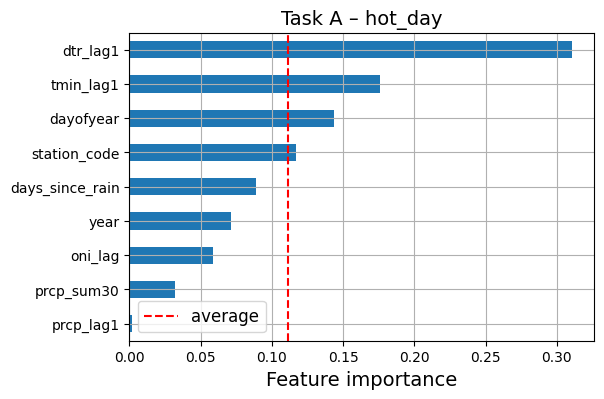

hot_day selected features: ['dtr_lag1', 'tmin_lag1', 'dayofyear', 'station_code']


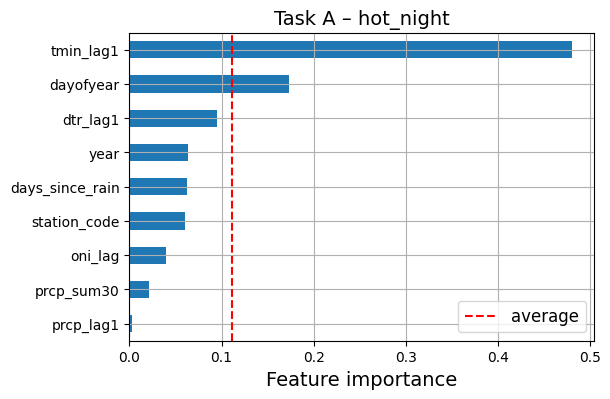

hot_night selected features: ['tmin_lag1', 'dayofyear']


In [24]:
def plot_importance(model, features, title):
    importance = pd.Series(model.feature_importances_, index=features).sort_values()
    importance.plot(kind="barh", figsize=(6, 4), grid=True)
    plt.axvline(importance.mean(), color="r", linestyle="--", label="average")
    plt.title(title)
    plt.xlabel("Feature importance")
    plt.legend()
    plt.show()
    return importance

def select_features(model, features):
    importance = pd.Series(model.feature_importances_, index=features)
    return importance[importance >= importance.mean()].sort_values(ascending=False).index.tolist()

a_selected = {}
for target in A_TARGETS:
    plot_importance(a_full_models[target], A_FEATURES, f"Task A – {target}")
    a_selected[target] = select_features(a_full_models[target], A_FEATURES)
    print(target, "selected features:", a_selected[target])

In [15]:
def plot_importance(model, features, title):
    importance = pd.Series(model.feature_importances_, index=features).sort_values()
    importance.plot(kind="barh", figsize=(6, 4), grid=True)
    plt.axvline(importance.mean(), color="r", linestyle="--", label="average")
    plt.title(title)
    plt.xlabel("Feature importance")
    plt.legend()
    plt.show()
    return importance

def select_features(model, features):
    importance = pd.Series(model.feature_importances_, index=features)
    return importance[importance >= importance.mean()].sort_values(ascending=False).index.tolist()

In [26]:
a_reduced_models = {}
for target in A_TARGETS:
    features = a_selected[target]
    a_reduced_models[target] = train_classifier(a_train[features], a_train[target])
    print("Trained reduced model for", target, "with", len(features), "features")

Trained reduced model for hot_day with 4 features
Trained reduced model for hot_night with 2 features


In [11]:
B_FEATURES = ["prev_hot_nights", "prev_mean_tmin", "avg5_hot_days",
              "prev_max_spell_days", "station_code", "year"]
B_TARGETS = ["hot_day_count", "hot_night_count"]

task_b = data.drop_duplicates(subset=["station", "year"])[B_FEATURES + B_TARGETS]
print("Station-years before removing missing values:", len(task_b))
task_b = task_b.dropna()
print("Station-years after removing missing values: ", len(task_b))

Station-years before removing missing values: 359
Station-years after removing missing values:  329


In [12]:
b_train = task_b[task_b["year"] <= TRAIN_END_YEAR]
b_test = task_b[task_b["year"] > TRAIN_END_YEAR]
print("Train rows:", len(b_train))
print("Test rows: ", len(b_test))

Train rows: 281
Test rows:  48


In [16]:
from sklearn.ensemble import RandomForestRegressor

def train_regressor(X_train, y_train):
    model = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
    model.fit(X_train, y_train)
    return model

b_full_models = {}
for target in B_TARGETS:
    b_full_models[target] = train_regressor(b_train[B_FEATURES], b_train[target])
    print("Trained full model for", target)

Trained full model for hot_day_count
Trained full model for hot_night_count


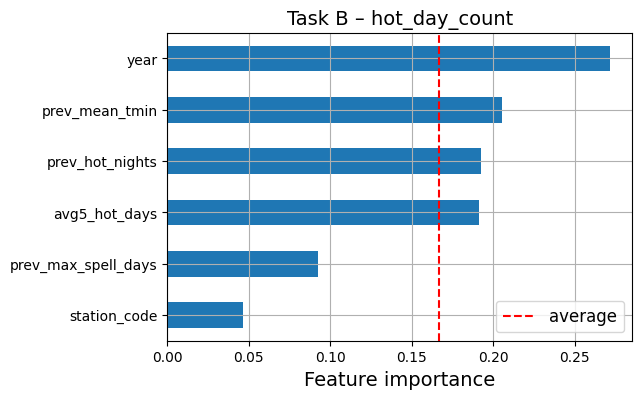

hot_day_count selected features: ['year', 'prev_mean_tmin', 'prev_hot_nights', 'avg5_hot_days']


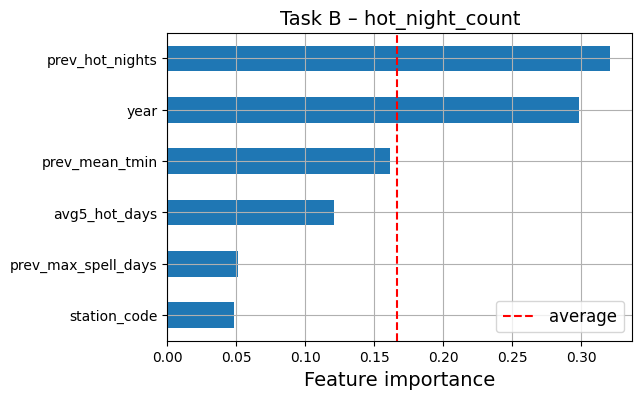

hot_night_count selected features: ['prev_hot_nights', 'year']


In [17]:
b_selected = {}
for target in B_TARGETS:
    plot_importance(b_full_models[target], B_FEATURES, f"Task B – {target}")
    b_selected[target] = select_features(b_full_models[target], B_FEATURES)
    print(target, "selected features:", b_selected[target])

In [18]:
b_reduced_models = {}
for target in B_TARGETS:
    features = b_selected[target]
    b_reduced_models[target] = train_regressor(b_train[features], b_train[target])
    print("Trained reduced model for", target, "with", len(features), "features")

Trained reduced model for hot_day_count with 4 features
Trained reduced model for hot_night_count with 2 features


In [27]:
import pickle

saved_models = []   # (file name, test X, test y)

def save_model(model, filename, X_test, y_test):
    pickle.dump(model, open(filename, "wb"))
    saved_models.append((filename, X_test, y_test))
    print("Saved", filename)

for target in A_TARGETS:
    save_model(a_full_models[target], f"taskA_{target}_full.sav",
               a_test[A_FEATURES], a_test[target])
    save_model(a_reduced_models[target], f"taskA_{target}_reduced.sav",
               a_test[a_selected[target]], a_test[target])

for target in B_TARGETS:
    save_model(b_full_models[target], f"taskB_{target}_full.sav",
               b_test[B_FEATURES], b_test[target])
    save_model(b_reduced_models[target], f"taskB_{target}_reduced.sav",
               b_test[b_selected[target]], b_test[target])

Saved taskA_hot_day_full.sav
Saved taskA_hot_day_reduced.sav
Saved taskA_hot_night_full.sav
Saved taskA_hot_night_reduced.sav
Saved taskB_hot_day_count_full.sav
Saved taskB_hot_day_count_reduced.sav
Saved taskB_hot_night_count_full.sav
Saved taskB_hot_night_count_reduced.sav


In [28]:
for filename, X_test, y_test in saved_models:
    loaded_model = pickle.load(open(filename, "rb"))
    result = loaded_model.score(X_test, y_test)
    print(f"{filename:35s} {result:.3f}")

taskA_hot_day_full.sav              0.932
taskA_hot_day_reduced.sav           0.932
taskA_hot_night_full.sav            0.926
taskA_hot_night_reduced.sav         0.859
taskB_hot_day_count_full.sav        -0.094
taskB_hot_day_count_reduced.sav     -0.047
taskB_hot_night_count_full.sav      -0.097
taskB_hot_night_count_reduced.sav   -0.166


In [ ]:
# =========================================================
# This is the third model we did specifically for Task A,
# we did Logistic regression model 
# =========================================================

import pandas as pd

data_root = "./Final_SOCal_dataset.csv"

data = pd.read_csv(data_root)
data.info()

In [ ]:
# remove features that will immediately leak the result
FEATURES = ["tmin_lag1", "dtr_lag1", "dayofyear", "days_since_rain", "oni_lag", "prcp_sum30", "prcp_lag1", "station_code"]

TRAIN_END_YEAR = 2015          # train: 1950–2015, test: 2016–2025
data = data.dropna()
train = data[data["year"] <= TRAIN_END_YEAR]
test = data[data["year"] > TRAIN_END_YEAR]

In [ ]:
# now create a logistic regression model for target_1
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.dummy import DummyClassifier
model_dummy = DummyClassifier(strategy="most_frequent")
model_dummy.fit(train[FEATURES], train["hot_day"])
print("always predict 0 score:", model_dummy.score(test[FEATURES], test["hot_day"]))

model1 = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
model1.fit(train[FEATURES], train["hot_day"])

model2 = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
model2.fit(train[FEATURES], train["hot_night"])

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

for (title, model) in [("Day", model1), ("Night", model2)]:
	proba = model.predict_proba(test[FEATURES])[:, 1]
	thresholds = np.arange(0.05, 0.96, 0.05)
	f1s = [f1_score(test["hot_day"], (proba >= t).astype(int)) for t in thresholds]
	precisions = [precision_score(test["hot_day"], (proba >= t).astype(int)) for t in thresholds]
	recalls = [recall_score(test["hot_day"], (proba >= t).astype(int)) for t in thresholds]

	best = thresholds[np.argmax(f1s)]

	plt.figure(figsize=(8, 6))
	plt.plot(thresholds, f1s, marker='o', label='F1 Score')
	plt.plot(thresholds, precisions, marker='o', label='Precision')
	plt.plot(thresholds, recalls, marker='o', label='Recall')
	plt.xlabel("Threshold")
	plt.ylabel("Score")
	plt.title(f"{title} metrics")
	plt.legend()
	plt.show()

	print("Best threshold for F1 score:", best)

	proba = model.predict_proba(test[FEATURES])[:, 1]

	y_pred = (proba >= best).astype(int)
	cm = confusion_matrix(test["hot_day"], y_pred, labels=[0, 1])
	auc = roc_auc_score(test["hot_day"], proba)
	print("Confusion Matrix:")
	print(cm)
	print("AUC: {:.2f}%".format(100 * auc))
	print("Precision: {:.2f}%".format(100 * precision_score(test["hot_day"], y_pred)))
	print("Recall: {:.2f}%".format(100 * recall_score(test["hot_day"], y_pred)))
	print("F1 Score: {:.2f}%".format(100 * f1_score(test["hot_day"], y_pred)))

In [ ]:
# save the normal models
import pickle
def save_model(model, test_feature, train_feature, test_target, train_target, filename):
    pickle.dump((model, test_feature, train_feature, test_target, train_target), open(filename, "wb"))
    print(f"Model saved to {filename}")
save_model(model1, test[FEATURES], train[FEATURES], test["hot_day"], train["hot_day"], "model_hot_day.sav")
save_model(model2, test[FEATURES], train[FEATURES], test["hot_night"], train["hot_night"], "model_hot_night.sav")

In [ ]:
# use importance to find out which features can be removed
from sklearn.inspection import permutation_importance

r = permutation_importance(model1, test[FEATURES], test["hot_day"],
                           scoring="average_precision", n_repeats=100, random_state=42)
imp = pd.Series(r.importances_mean, index=FEATURES).sort_values()
err = pd.Series(r.importances_std, index=FEATURES)[imp.index]

imp.plot(kind="barh", xerr=err, figsize=(6, 4), grid=True)
plt.xlabel("Importance")
plt.show()

useful_features = []
for feature in FEATURES:
    if imp[feature] > 0.01:
        useful_features.append(feature)
print("Useful features:", useful_features)

In [ ]:
# refit on the useful features
model1_refit = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
model1_refit.fit(train[useful_features], train["hot_day"])

model2_refit = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
model2_refit.fit(train[useful_features], train["hot_night"])

In [ ]:
import pickle
def save_model(model, test_feature, train_feature, test_target, train_target, filename):
    pickle.dump((model, test_feature, train_feature, test_target, train_target), open(filename, "wb"))
    print(f"Model saved to {filename}")
save_model(model1_refit, test[useful_features], train[useful_features], test["hot_day"], train["hot_day"], "model_hot_day_reduced.sav")
save_model(model2_refit, test[useful_features], train[useful_features], test["hot_night"], train["hot_night"], "model_hot_night_reduced.sav")

In [ ]:
for model, test_feature, train_feature, test_target, train_target in pickle.load(open("model_hot_day_reduced.sav", "rb")), pickle.load(open("model_hot_night_reduced.sav", "rb")), pickle.load(open("model_hot_day.sav", "rb")), pickle.load(open("model_hot_night.sav", "rb")):
	result = model.score(test_feature, test_target)
	print(result)

In [ ]:
# =======================================================================
# We then used a fourth model specifically for Task B, for which we 
# used Linear Regression
# =======================================================================
import pickle
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

data_root = "/Users/samuelgonzalez/Documents/Computer Science/CSUF/CPSC 483/Project/Preprocessed Data/Final_SOCal_dataset.csv"

df = pd.read_csv(data_root)
df.info()

In [ ]:
b_features = ["prev_hot_nights", "prev_mean_tmin", "avg5_hot_days",
              "prev_max_spell_days", "station_code", "year"]
b_targets = ["hot_day_count", "hot_night_count"]

task_b = df.drop_duplicates(subset=["station", "year"])[b_features + b_targets]
print("Station-years before removing missing values:", len(task_b))
task_b = task_b.dropna()
print("Station-years after removing missing values: ", len(task_b))

In [ ]:
test_end = 2015
b_train = task_b[task_b["year"] <= test_end]
b_test = task_b[task_b["year"] > test_end]

In [ ]:
b_full_model = {}
for target in b_targets:
    model = LinearRegression()
    model.fit(b_train[b_features], b_train[target])
    b_full_model[target] = model

In [ ]:
b_selected = {}
for target in b_targets:
    importance = pd.Series(b_full_model[target].coef_, index=b_features).sort_values()
    importance.plot(kind="barh", figsize=(6, 4), grid=True)
    plt.axvline(importance.mean(), color="r", linestyle="--", label="average")
    plt.title(f"Task B - {target}")
    plt.xlabel("Feature importance")
    plt.legend()
    plt.show()
    b_selected[target] = importance[importance >= importance.mean()].sort_values(ascending=False).index.tolist()
    

In [ ]:
b_reduced_models = {}
for target in b_targets:
    features = b_selected[target]
    model = LinearRegression()
    model.fit(b_train[features], b_train[target])
    b_reduced_models[target] = model
    print("Trained reduced model for", target, "with", len(features), "features")

In [ ]:
saved_models = []   # (file name, test X, test y)

def save_model(model, filename, X_test, y_test):
    pickle.dump(model, open(filename, "wb"))
    saved_models.append((filename, X_test, y_test))
    print("Saved", filename)

for target in b_targets:
    save_model(b_full_models[target], f"taskB_{target}_full.sav",
               b_test[b_features], b_test[target])
    save_model(b_reduced_models[target], f"taskB_{target}_reduced.sav",
               b_test[b_selected[target]], b_test[target])

In [ ]:
for filename, X_test, y_test in saved_models:
    loaded_model = pickle.load(open(filename, "rb"))
    result = loaded_model.score(X_test, y_test)
    print(f"{filename:35s} {result:.3f}")

In [ ]:
# ==============================================================
# For another model we used KNN Regressor for task B
# ==============================================================
K = 11   # number of neighbors

def make_knn(features):
    numeric = [f for f in features if f != "station_code"]
    steps = [(StandardScaler(), numeric)]
    if "station_code" in features:
        steps.append((OneHotEncoder(handle_unknown="ignore"), ["station_code"]))
    prep = make_column_transformer(*steps)
    return make_pipeline(prep, KNeighborsRegressor(n_neighbors=K))

In [ ]:
b_full_model = {}
for target in b_targets:
    model = make_knn(b_features)
    model.fit(b_train[b_features], b_train[target])
    b_full_model[target] = model
    print("Trained full model for", target)

In [ ]:
b_features = ["prev_hot_nights", "prev_mean_tmin", "avg5_hot_days",
              "prev_max_spell_days", "station_code", "year"]
b_targets = ["hot_day_count", "hot_night_count"]

task_b = df.drop_duplicates(subset=["station", "year"])[b_features + b_targets]
print("Station-years before removing missing values:", len(task_b))
task_b = task_b.dropna()
print("Station-years after removing missing values: ", len(task_b))

In [ ]:
train_end = 2015
b_train = task_b[task_b["year"] <= train_end]
b_test = task_b[task_b["year"] > train_end]
print("Train rows:", len(b_train))
print("Test rows: ", len(b_test))

In [ ]:
b_selected = {}
for target in b_targets:
    result = permutation_importance(
        b_full_model[target], b_train[b_features], b_train[target], n_repeats=10, random_state=42
    )
    importance = pd.Series(result.importances_mean, index=b_features).sort_values()
    importance.plot(kind="barh", figsize=(6, 4), grid=True)
    plt.axvline(importance.mean(), color="r", linestyle="--", label="average")
    plt.title(f"Task B - {target}")
    plt.xlabel("Feature importance")
    plt.legend()
    plt.show()
    b_selected[target] = importance[importance >= importance.mean()].sort_values(ascending=False).index.tolist()
    print(target, "selected features:", b_selected[target])

In [ ]:
b_reduced_models = {}
for target in b_targets:
    features = b_selected[target]
    model = make_knn(features)
    model.fit(b_train[features], b_train[target])
    b_reduced_models[target] = model
    print("Trained reduced model for", target, "with", len(features), "features")

In [ ]:
saved_models = []   # (file name, test X, test y)

for target in b_targets:
    filename = f"taskB_knn_{target}_full.sav"
    pickle.dump(b_full_model[target], open(filename, "wb"))
    saved_models.append((filename, b_test[b_features], b_test[target]))

    filename = f"taskB_knn_{target}_reduced.sav"
    pickle.dump(b_reduced_models[target], open(filename, "wb"))
    saved_models.append((filename, b_test[b_selected[target]], b_test[target]))

for filename, X_test, y_test in saved_models:
    loaded_model = pickle.load(open(filename, "rb"))
    result = loaded_model.score(X_test, y_test)
    print(f"{filename:40s} {result:.3f}")

In [ ]:
# =============================================================
# For another model we used KNN Classifier for Task A
# =============================================================
